In [6]:
import pandas as pd 

salesdf=pd.read_csv("advanced_sales_practice.csv")
salesdf.head(5)
salesdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    100 non-null    str    
 1   Date              100 non-null    str    
 2   Customer_ID       100 non-null    str    
 3   Product_Category  100 non-null    str    
 4   Items_Ordered     100 non-null    int64  
 5   Price_Per_Item    92 non-null     float64
 6   Payment_Method    94 non-null     str    
 7   Shipping_Status   100 non-null    str    
 8   Customer_Rating   88 non-null     float64
 9   Discount_Applied  100 non-null    bool   
 10  Revenue           92 non-null     float64
dtypes: bool(1), float64(3), int64(1), str(6)
memory usage: 8.0 KB


In [7]:
salesdf["Date"]=pd.to_datetime(salesdf['Date'])



In [8]:
salesdf['Revenue']=salesdf['Items_Ordered']*salesdf["Price_Per_Item"]

In [9]:
salesdf.head()

,Transaction_ID,Date,Customer_ID,Product_Category,Items_Ordered,Price_Per_Item,Payment_Method,Shipping_Status,Customer_Rating,Discount_Applied,Revenue
0,TXN_1000,1970-01-01 00:00:00.000001970,CUST_106,Clothing,4,18.86,UPI,Shipped,1.0,False,75.44
1,TXN_1001,1970-01-01 00:00:00.000001970,CUST_103,Clothing,3,252.01,Credit Card,Processing,4.0,True,756.03
2,TXN_1002,1970-01-01 00:00:00.000001970,CUST_112,Books,1,97.62,Cash,Shipped,NaN,False,97.62
3,TXN_1003,1970-01-01 00:00:00.000001970,CUST_114,Books,4,189.57,Credit Card,Delivered,1.0,False,758.28
4,TXN_1004,1970-01-01 00:00:00.000001970,CUST_110,Electronics,1,374.64,Credit Card,Delivered,1.0,True,374.64


In [10]:
salesdf.to_csv("advanced_sales_practice.csv",index=False)

In [11]:
salesdf.isna()

,Transaction_ID,Date,Customer_ID,Product_Category,Items_Ordered,Price_Per_Item,Payment_Method,Shipping_Status,Customer_Rating,Discount_Applied,Revenue
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
95,False,False,False,False,False,True,False,False,False,False,True
96,False,False,False,False,False,False,False,False,False,False,False
97,False,False,False,False,False,False,False,False,False,False,False
98,False,False,False,False,False,False,True,False,False,False,False


In [12]:
salesdf.describe()


,Date,Items_Ordered,Price_Per_Item,Customer_Rating,Revenue
count,100,100.000000,92.000000,88.000000,92.000000
mean,1970-01-01 00:00:00.000001970,2.700000,240.420000,3.113636,687.784457
min,1970-01-01 00:00:00.000001970,1.000000,12.540000,1.000000,25.080000
25%,1970-01-01 00:00:00.000001970,1.000000,130.162500,2.000000,233.887500
50%,1970-01-01 00:00:00.000001970,3.000000,229.455000,3.000000,459.030000
75%,1970-01-01 00:00:00.000001970,4.000000,354.607500,5.000000,967.505000
max,1970-01-01 00:00:00.000001970,5.000000,497.330000,5.000000,2486.650000
std,NaN,1.344649,143.323026,1.541993,625.547729


In [13]:
salesdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    100 non-null    str           
 1   Date              100 non-null    datetime64[ns]
 2   Customer_ID       100 non-null    str           
 3   Product_Category  100 non-null    str           
 4   Items_Ordered     100 non-null    int64         
 5   Price_Per_Item    92 non-null     float64       
 6   Payment_Method    94 non-null     str           
 7   Shipping_Status   100 non-null    str           
 8   Customer_Rating   88 non-null     float64       
 9   Discount_Applied  100 non-null    bool          
 10  Revenue           92 non-null     float64       
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), str(5)
memory usage: 8.0 KB


In [14]:
salesdf.isna().sum()

Transaction_ID       0
Date                 0
Customer_ID          0
Product_Category     0
Items_Ordered        0
Price_Per_Item       8
Payment_Method       6
Shipping_Status      0
Customer_Rating     12
Discount_Applied     0
Revenue              8
dtype: int64

In [15]:
salesdf['Price_Per_Item']=salesdf['Price_Per_Item'].interpolate()

In [16]:
salesdf.groupby(["Product_Category"])["Price_Per_Item"].mean()

Product_Category
Books             242.685238
Clothing          195.562619
Electronics       251.817000
Home & Kitchen    245.035167
Sports            267.052500
Name: Price_Per_Item, dtype: float64

In [17]:
revenueByCategory=salesdf.groupby(["Product_Category"]).agg({'Price_Per_Item':'mean','Items_Ordered':'sum'})

In [18]:
revenueByCategory 


,Price_Per_Item,Items_Ordered
Product_Category,,
Books,242.685238,46
Clothing,195.562619,41
Electronics,251.817000,71
Home & Kitchen,245.035167,56
Sports,267.052500,56


In [19]:
salesdf.corr(numeric_only=True)

,Items_Ordered,Price_Per_Item,Customer_Rating,Discount_Applied,Revenue
Items_Ordered,1.000000,0.168071,0.112720,0.041991,0.661506
Price_Per_Item,0.168071,1.000000,0.118540,0.024531,0.780487
Customer_Rating,0.112720,0.118540,1.000000,-0.109503,0.259856
Discount_Applied,0.041991,0.024531,-0.109503,1.000000,0.070989
Revenue,0.661506,0.780487,0.259856,0.070989,1.000000


In [20]:
import matplotlib
print(matplotlib.__version__)

3.11.0


In [23]:
import matplotlib.pyplot as plt

plt.style.use("default")

salesdf.head()

,Transaction_ID,Date,Customer_ID,Product_Category,Items_Ordered,Price_Per_Item,Payment_Method,Shipping_Status,Customer_Rating,Discount_Applied,Revenue
0,TXN_1000,1970-01-01 00:00:00.000001970,CUST_106,Clothing,4,18.86,UPI,Shipped,1.0,False,75.44
1,TXN_1001,1970-01-01 00:00:00.000001970,CUST_103,Clothing,3,252.01,Credit Card,Processing,4.0,True,756.03
2,TXN_1002,1970-01-01 00:00:00.000001970,CUST_112,Books,1,97.62,Cash,Shipped,NaN,False,97.62
3,TXN_1003,1970-01-01 00:00:00.000001970,CUST_114,Books,4,189.57,Credit Card,Delivered,1.0,False,758.28
4,TXN_1004,1970-01-01 00:00:00.000001970,CUST_110,Electronics,1,374.64,Credit Card,Delivered,1.0,True,374.64


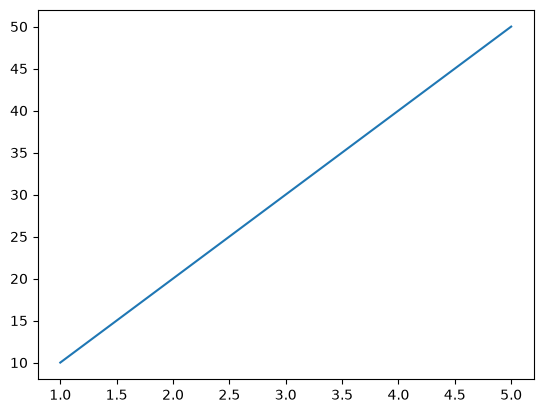

In [25]:
plt.plot([1,2,3,4,5],[10,20,30,40,50])
plt.show()

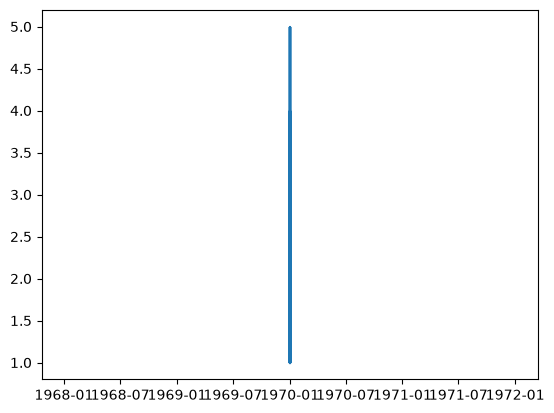

In [28]:
plt.plot(salesdf['Date'],salesdf['Items_Ordered'])

<BarContainer object of 100 artists>

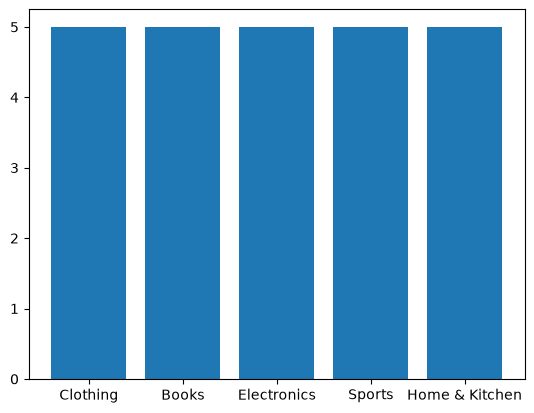

In [29]:
plt.bar(salesdf['Product_Category'],salesdf['Items_Ordered'])

In [32]:
salesdf.groupby('Product_Category')["Items_Ordered"].count()

Product_Category
Books             21
Clothing          14
Electronics       25
Home & Kitchen    20
Sports            20
Name: Items_Ordered, dtype: int64

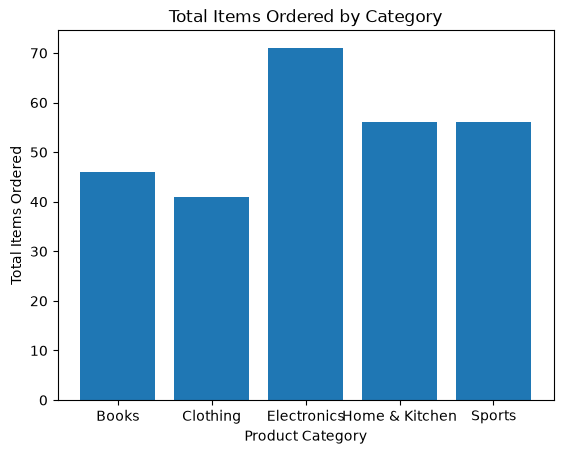

In [33]:
# 1. Group by category and sum up the items ordered
category_totals = salesdf.groupby('Product_Category')['Items_Ordered'].sum()

# 2. Plot the aggregated data
plt.bar(category_totals.index, category_totals.values)

# 3. Add clean labels so it looks professional
plt.xlabel("Product Category")
plt.ylabel("Total Items Ordered")
plt.title("Total Items Ordered by Category")

plt.show()